# GLACE — exploration 
This code is to explore the potential of the model GLAC.

In [1]:
import sys, os
ROOT = os.path.dirname(os.path.abspath('')) # ajoute la racine du projet quel que soit l'endroit d'où le notebook est lancé
sys.path.insert(0, ROOT)
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from types import SimpleNamespace
from glace.main import build_params
from glace.core import run_simulation
from glace.figures import plot_profiles, plot_snapshots, plot_attribution, plot_data_vs_model
print('✓ imports OK')

✓ imports OK


## Paramètres

In [2]:
# ── Physique du gaz ───────────────────────────────────────────────────────────
P_diss  = 5e6        # pression de dissociation des clathrates   [Pa]
S_Ar    = 10e-9      # solubilité Ar dans le réseau              [mol m⁻³ Pa⁻¹]

# ── Site ─────────────────────────────────────────────────────────────────────
TAC     = 4.856e-5   # total air content (données labo)          [m³_STP kg⁻¹]
b_acc   = 0.35       # taux d'accumulation                       [m yr⁻¹]
H_ice   = 1387.0     # épaisseur de glace                        [m]    
p_llib  = 3          # paramètre de forme Lliboutry              [-]

# ── Transport ─────────────────────────────────────────────────────────────────
D_m2s       = 1e-11  # diffusivité dans le réseau                [m² s⁻¹]
flux_bottom = 6e-7   # flux basal Ar                             [mol m⁻² yr⁻¹]

# ── Gas loss ──────────────────────────────────────────────────────────────────
GAS_LOSS_MODE = 'data'   # 'none' ou 'data'
gas_loss_data = 1.8e-6   # taux max (mode 'data' seulement)      [yr⁻¹]
z_char        = 8.0      # hauteur caractéristique               [m]
z_gl_limit    = 20.0     # limite supérieure de la zone          [m]

# ── Grille et temps ───────────────────────────────────────────────────────────
nz = 101
Z  = 30.0            # domaine au-dessus du bed                  [m]
T  = 1e5             # durée totale de simulation                [yr]
dt = 3.0             # pas de temps                              [yr]

# ── Constantes ────────────────────────────────────────────────────────────────

rho_ice = 917.0
Vm_STP  = 22.414e-3
X_atm   = 0.934e-2   # référence atmosphérique (non utilisé pour BC/IC => data lab)

## Lancement de la simulation

In [3]:
p = SimpleNamespace(
    P_diss=P_diss, S_Ar=S_Ar, TAC=TAC, b_acc=b_acc, H_ice=H_ice, p_llib=p_llib,
    D_m2s=D_m2s, flux_bottom=flux_bottom,
    GAS_LOSS_MODE=GAS_LOSS_MODE, gas_loss_data=gas_loss_data,
    z_char=z_char, z_gl_limit=z_gl_limit,
    nz=nz, Z=Z, T=T, dt=dt,
    rho_ice=rho_ice, Vm_STP=Vm_STP, X_atm=X_atm,
)
sim = build_params(p)
result = run_simulation(sim, return_full=True)
print(f'Simulation terminée — {sim["nt"]} pas de temps')

  Umax          = -3.7851e-02 m/yr
  CFL           = 0.379  ✓
  Diffusion no. = 0.0105
  Gas loss mode   = data  (λ_max = 1.80e-06 yr⁻¹, z_char = 8.0 m)
  Surface BC/IC   = 0.9658 % Ar  (topmost data point, z = 26.55 m)
Simulation terminée — 33333 pas de temps


## Figures

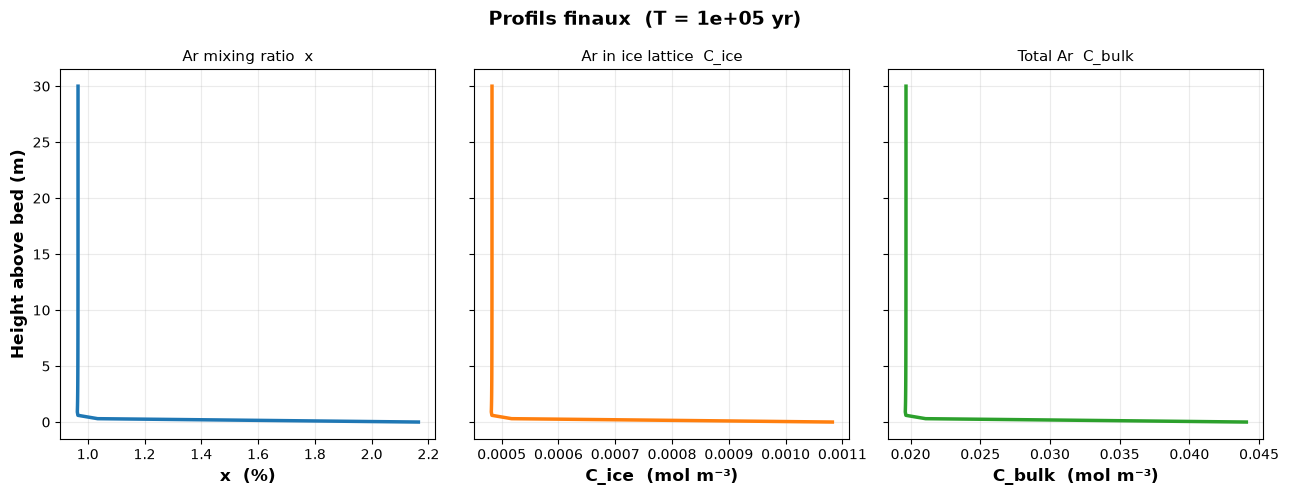

In [4]:
fig1 = plot_profiles(result, title=f'Profils finaux  (T = {T:.2g} yr)')
plt.show()

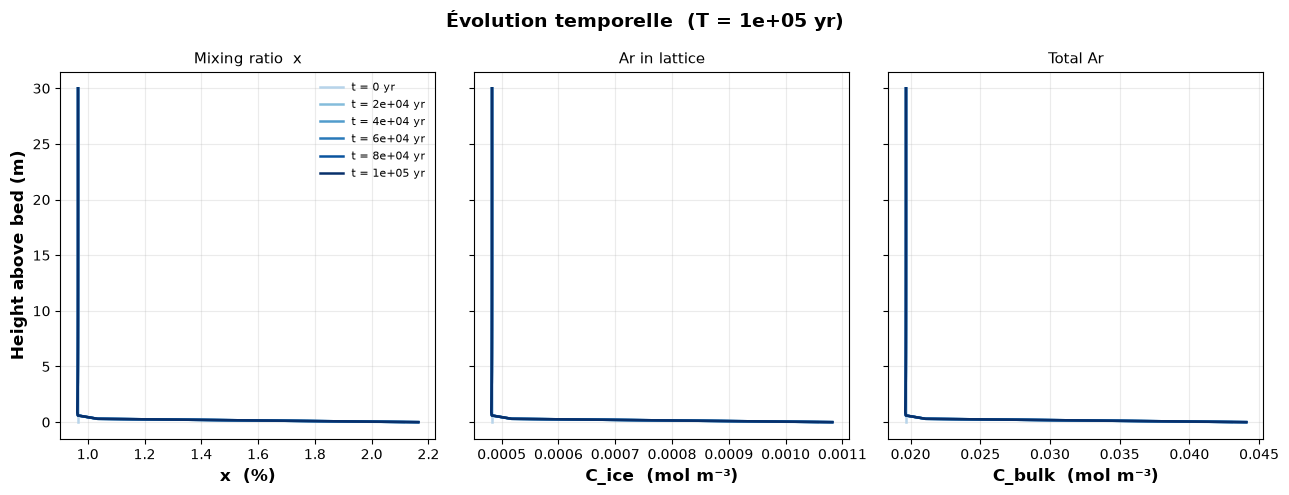

In [5]:
fig2 = plot_snapshots(result, n_snap=6, title=f'Évolution temporelle  (T = {T:.2g} yr)')
plt.show()

donc rien de bien waaw on voit que la physique est respectée : le profil est ce que je voudrais avoir mais bon ce n'est pas du tout à l'équilibre : la diffusion a besoin de trop de temps >< advection (cfr : test ci dessous)

---
## Diffusion seule — équilibre et temps caractéristique

La diffusivité effective est réduite par la fraction dissoute dans la glace :

$$D_{\text{eff}} = D \times \alpha, \quad \alpha = \frac{p_S}{p_S + n_{\text{air}}} \approx 2.46\%$$

Le temps pour atteindre l'état stationnaire par diffusion pure :

$$\tau_{\text{diff}} = \frac{Z^2}{D_{\text{eff}}} = \frac{30^2}{7.74 \times 10^{-6}} \approx \mathbf{116 \text{ Myr}}$$

**Conclusion** : à l'échelle glaciaire (~800 kyr), la diffusion seule n'atteint jamais l'état stationnaire.  
La figure ci-dessous compare le profil transitoire à T=1e5 yr avec la solution analytique à l'équilibre (calculée une seule fois, figure pré-enregistrée car 117 Myr est trèèès long pour une simulation).


alpha     = 2.4550 %
D_eff     = 7.7420e-06 m²/yr
tau_diff  = 1.162e+08 yr  =  116 Myr

Figure pré-calculée (run unique, pas de recalcul) :


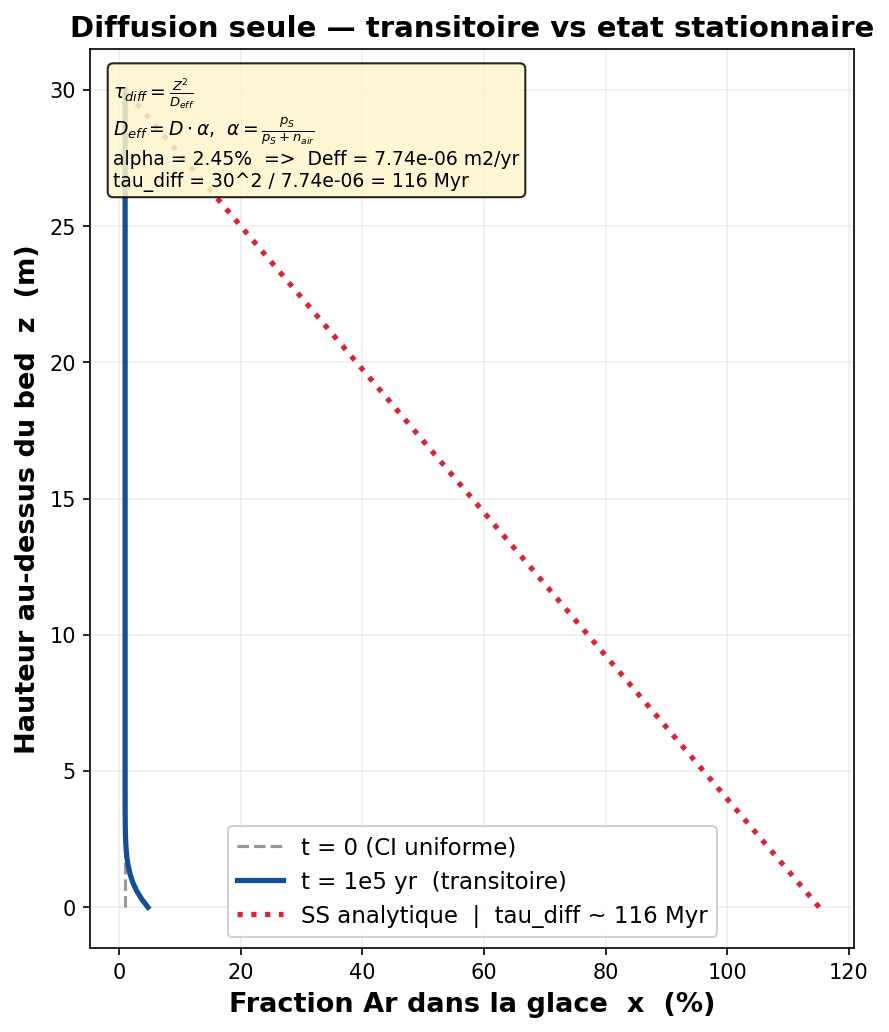

In [6]:
# ── Calcul de tau_diff (analytique, instantané) ──────────────────────────────
pS_val  = P_diss * S_Ar
n_air   = TAC * rho_ice / Vm_STP
alpha   = pS_val / (pS_val + n_air)
D_eff   = D_m2s * 3.1536e7 * alpha    # m²/yr

tau_diff = Z**2 / D_eff
print(f"alpha     = {alpha*100:.4f} %")
print(f"D_eff     = {D_eff:.4e} m²/yr")
print(f"tau_diff  = {tau_diff:.3e} yr  =  {tau_diff/1e6:.0f} Myr")
print()
print("Figure pré-calculée (run unique, pas de recalcul) :")

# Affiche la figure pré-enregistrée
from IPython.display import Image, display
display(Image(filename='../figures/fig_diffusion_SS.png', width=500))


---
## Advection — temps pour atteindre le SS

Avec advection, le temps de résidence à la hauteur z est :

$$\tau_{\text{res}}(z) = \frac{H}{(p+2)\,b_{\text{acc}}} \ln\!\left(\frac{Z}{z}\right)$$

À z = 1 m : **τ_res ~ 2 700 yr**. Le SS est atteint en ~5–10 × τ_res soit **~15 000–27 000 yr**.
Figure pré-calculée (run unique T = 30 000 yr) :

tau_res(z=1m) = 2696 yr
SS attendu    ~ 13478 – 26957 yr


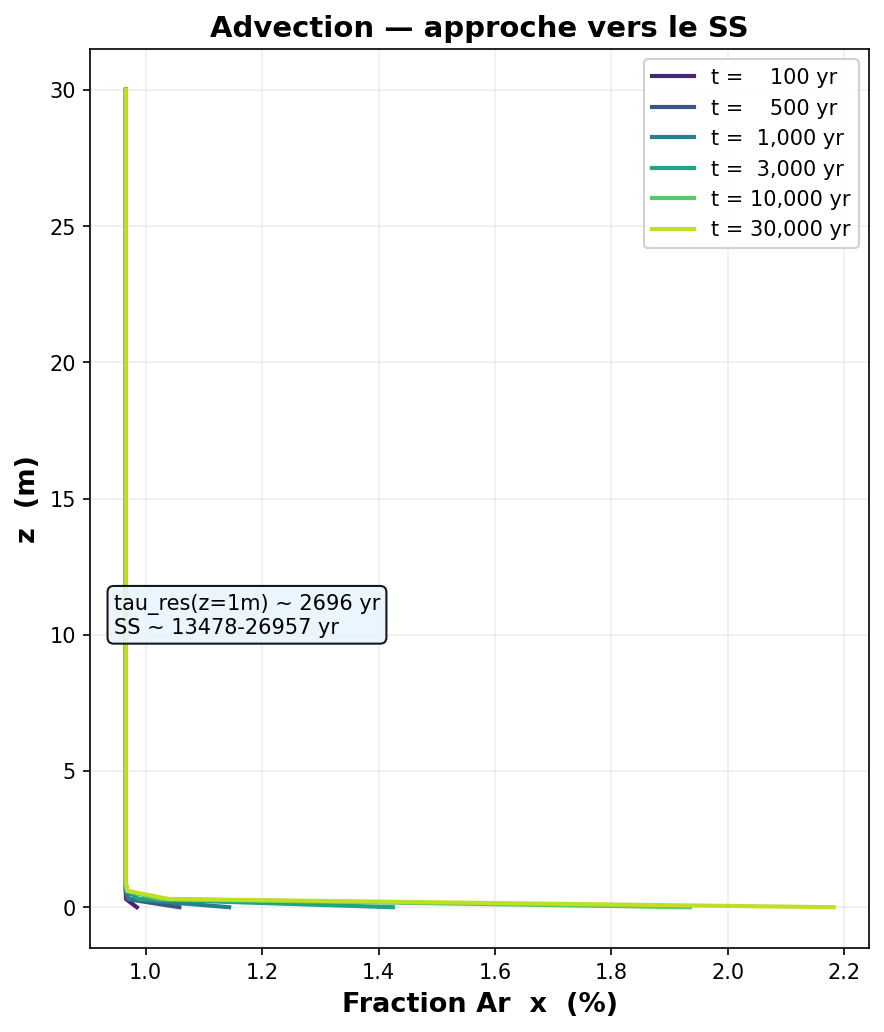

In [7]:
# Calcul analytique de tau_res
H_ice = 1387.0; p_llib = 3; b_acc = 0.35; Z = 30.0
tau_res_1m = H_ice / ((p_llib+2)*b_acc) * np.log(Z / 1.0)
print("tau_res(z=1m) = {:.0f} yr".format(tau_res_1m))
print("SS attendu    ~ {:.0f} – {:.0f} yr".format(5*tau_res_1m, 10*tau_res_1m))

from IPython.display import Image, display
display(Image(filename='../figures/fig_advection_SS.png', width=450))

---
## Nombre de Péclet

Calculé sur l'ensemble du profil :
$$Pe_{\text{global}} = \frac{|u_{\text{max}}| \cdot Z}{D_{\text{eff}}} \approx 1.5 \times 10^5 \gg 1$$
→ **l'advection domine à l'échelle du profil entier**.

Mais ce qui nous intéresse c'est le **dernier mètre au fond** : la vitesse $u(z) \to 0$ au lit gelé et c'est là qu'arrive le flux basal d'Ar. Localement $Pe_{\text{local}} \to 0$ → **c'est la diffusion qui redistribue le signal d'enrichissement basal** avant qu'il ne soit advecté vers le haut. C'est dans cette zone que se joue l'essentiel de la physique.


In [ ]:
# ── Nombre de Péclet global vs local au fond ─────────────────────────────────
pS_val  = P_diss * S_Ar
n_air_v = TAC * rho_ice / Vm_STP
alpha   = pS_val / (pS_val + n_air_v)
D_eff   = D_m2s * 3.1536e7 * alpha      # [m²/yr]

u_max   = b_acc * (p_llib + 2) / H_ice * Z   # vitesse au sommet du profil [m/yr]
Pe_glob = u_max * Z / D_eff

z_basal = 1.0                                 # dernier mètre
u_basal = b_acc * (p_llib + 2) / H_ice * z_basal
Pe_loc  = u_basal * z_basal / D_eff

print(f'D_eff        = {D_eff:.3e} m²/yr  (alpha = {alpha*100:.2f} %)')
print(f'u_max (z=Z)  = {u_max:.4f} m/yr')
print(f'Pe_global    = {Pe_glob:.2e}  >>  1  → advection domine sur tout le profil')
print()
print(f'u (z=1 m)    = {u_basal:.2e} m/yr')
print(f'Pe_local     = {Pe_loc:.3f}  <<  1  → diffusion domine dans le dernier mètre')


---
## Gas loss — ajout et comparaison

Comparaison modèle sans vs avec gas loss (λ(z) = λ_max · exp(−z/z_char)).
Figure pré-calculée (T = 1e5 yr) :

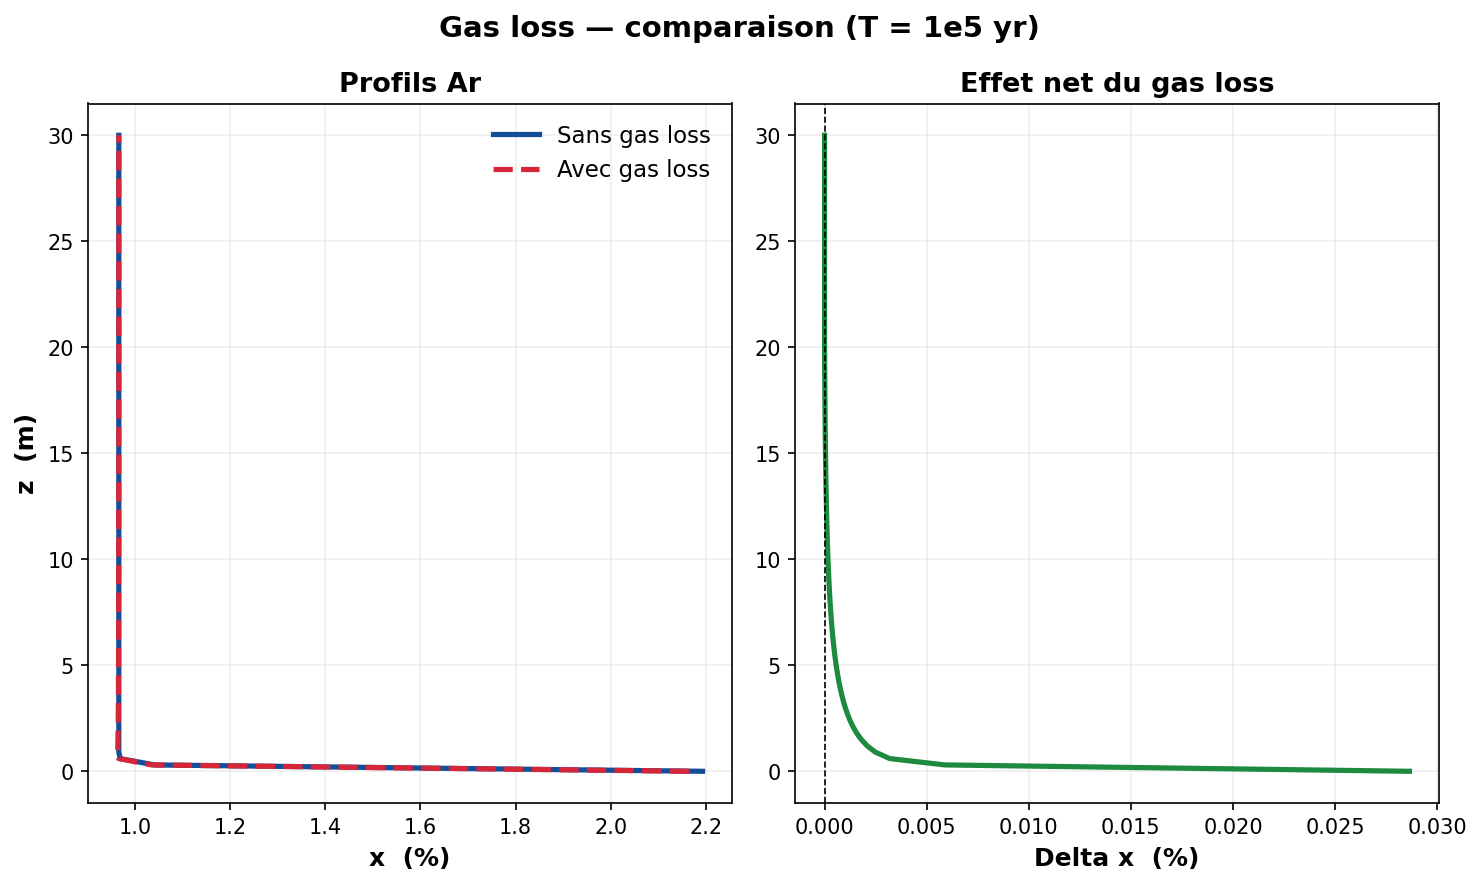

Gas loss_data = 1.80e-06 yr-1  |  z_char = 8.0 m  |  z_limit = 20.0 m
Effet net max sur x : ~0.03 % (Ar noble gas, effet compense par flux basal)


In [10]:
from IPython.display import Image, display
display(Image(filename='../figures/fig_gasloss.png', width=600))
print("Gas loss_data = {:.2e} yr-1  |  z_char = {} m  |  z_limit = {} m".format(
      gas_loss_data, z_char, z_gl_limit))
print("Effet net max sur x : ~0.03 % (Ar noble gas, effet compense par flux basal)")

---
## Front de diffusion basal

La profondeur de pénétration du signal depuis le fond vaut $\delta z \sim \sqrt{D_{\text{eff}} \cdot T}$ :

| Temps | Pénétration |
|-------|-------------|
| 10 000 yr | ~0.3 m |
| 100 000 yr | ~0.9 m |
| 800 000 yr | ~2.5 m |
| 116 Myr (τ_diff) | 30 m (équilibre) |

À 800 000 ans, la diffusion n'a pénétré que ~2.5 m depuis le fond — exactement la zone enrichie en Ar dans les données.


In [16]:
#from IPython.display import Image, display

# Front de diffusion : dz(T) = sqrt(D_eff * T)
#pS_val = P_diss * S_Ar
#n_air_val = TAC * rho_ice / Vm_STP
#alpha   = pS_val / (pS_val + n_air_val)
#D_eff   = D_m2s * 3.1536e7 * alpha

#print(f'D_eff = alpha * D = {alpha*100:.3f}% * {D_m2s:.0e} m2/s = {D_eff:.3e} m2/yr')
#print()
#for T_yr in [1e4, 1e5, 8e5, 1.16e8]:
    dz = (D_eff * T_yr)**0.5
    print(f'  T = {T_yr:.2g} yr  -->  dz = {dz:.2f} m')

#print()
#print('--- Front de diffusion depuis le fond ---')
#display(Image(filename='../figures/fig_diffusion_front.png', width=750))
#print('--- Partition Ar dissous vs clathrates (5 m basaux) ---')
#display(Image(filename='../figures/fig_basal_partition.png', width=750))
#print('--- Schema conceptuel des mecanismes de transport ---')
#display(Image(filename='../figures/fig_transport_schema.png', width=700))

IndentationError: unexpected indent (2218847979.py, line 12)

---
## Paramétrisation de la vitesse d'advection — Lliboutry vs Dansgaard-Johnsen

Deux formulations physiques existent pour le profil de vitesse verticale dans les 30 m basaux :

**Lliboutry (1979)** — lit gelé, profil polynomial sur toute l'épaisseur :
$$w(\zeta) = -\dot{b} \left[ (p+2)\zeta - (p+2)\zeta^{p+1} + \zeta^{p+2} \right], \quad \zeta = z/H_{\text{ice}}$$

**Dansgaard-Johnsen (1969)** — en dessous du *kink* ($h_{\text{kink}} \approx 400$ m à Camp Century), la vitesse est approximativement constante :
$$u_{\text{basal}} = -\frac{b_{\text{acc}} \cdot h_{\text{kink}}}{2\,H_{\text{ice}}} \approx -0.050 \text{ m/yr}$$
Dans notre domaine de 30 m, le profil suit une loi quadratique : $u(z) = u_{\text{basal}} \cdot (z/Z)^2$

| Paramètre | Lliboutry | Dansgaard-Johnsen |
|-----------|-----------|-------------------|
| $U_{\text{max}}$ au sommet du domaine | −3.785 cm/yr | −5.047 cm/yr |
| Forme du profil | polynomial ordre $p+2$ | quadratique |
| Référence | Lliboutry (1979) | Hammer et al. (1978) |

L'écart de $U_{\text{max}}$ (~33 %) a une influence **significative** sur le profil Ar final (~1.4 % Ar d'écart max).


Umax Lliboutry = -3.7851 cm/yr
Umax DJ        = -5.0469 cm/yr
Ecart relatif  = 33.3 %

--- Profils de vitesse ---


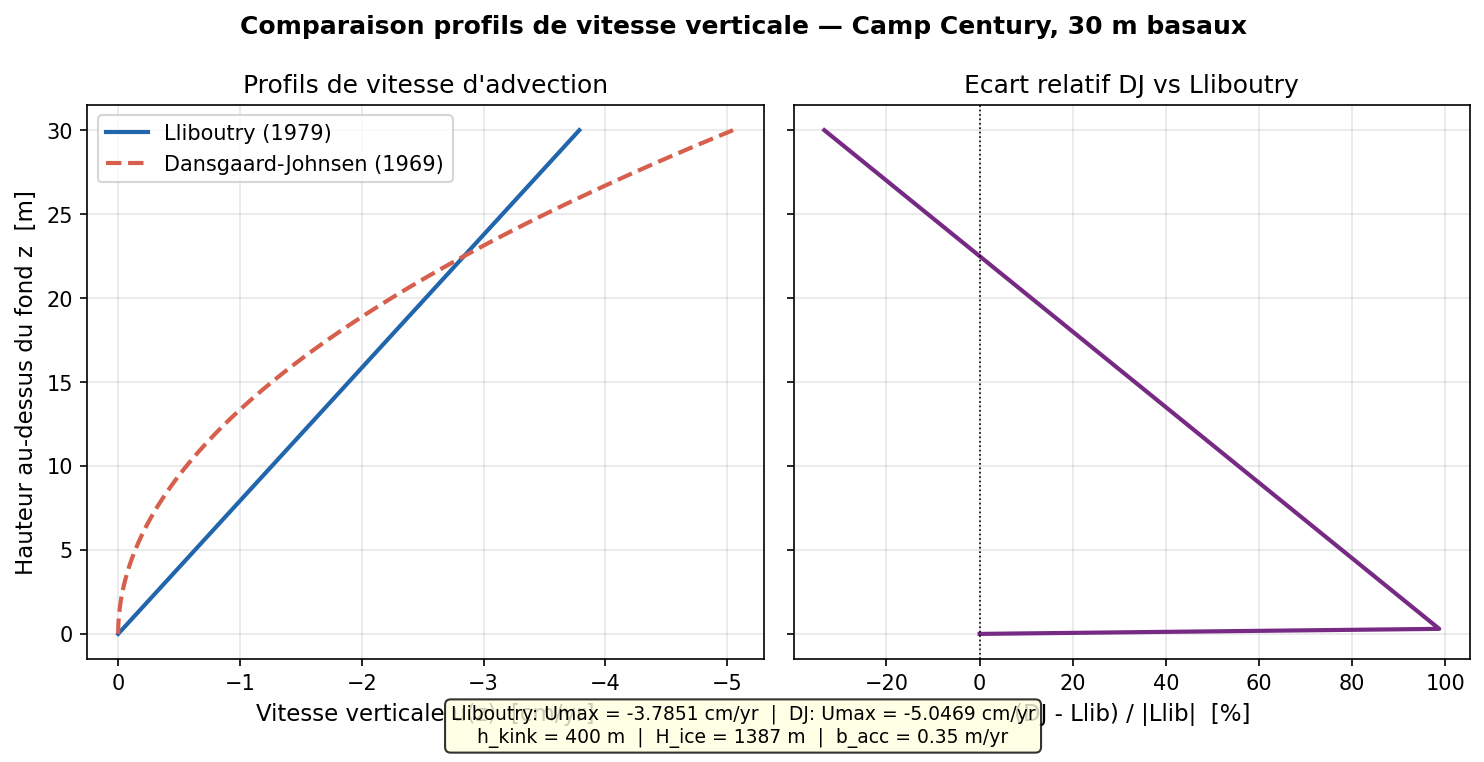

--- Effet sur le profil Ar (T = 1e5 yr) ---


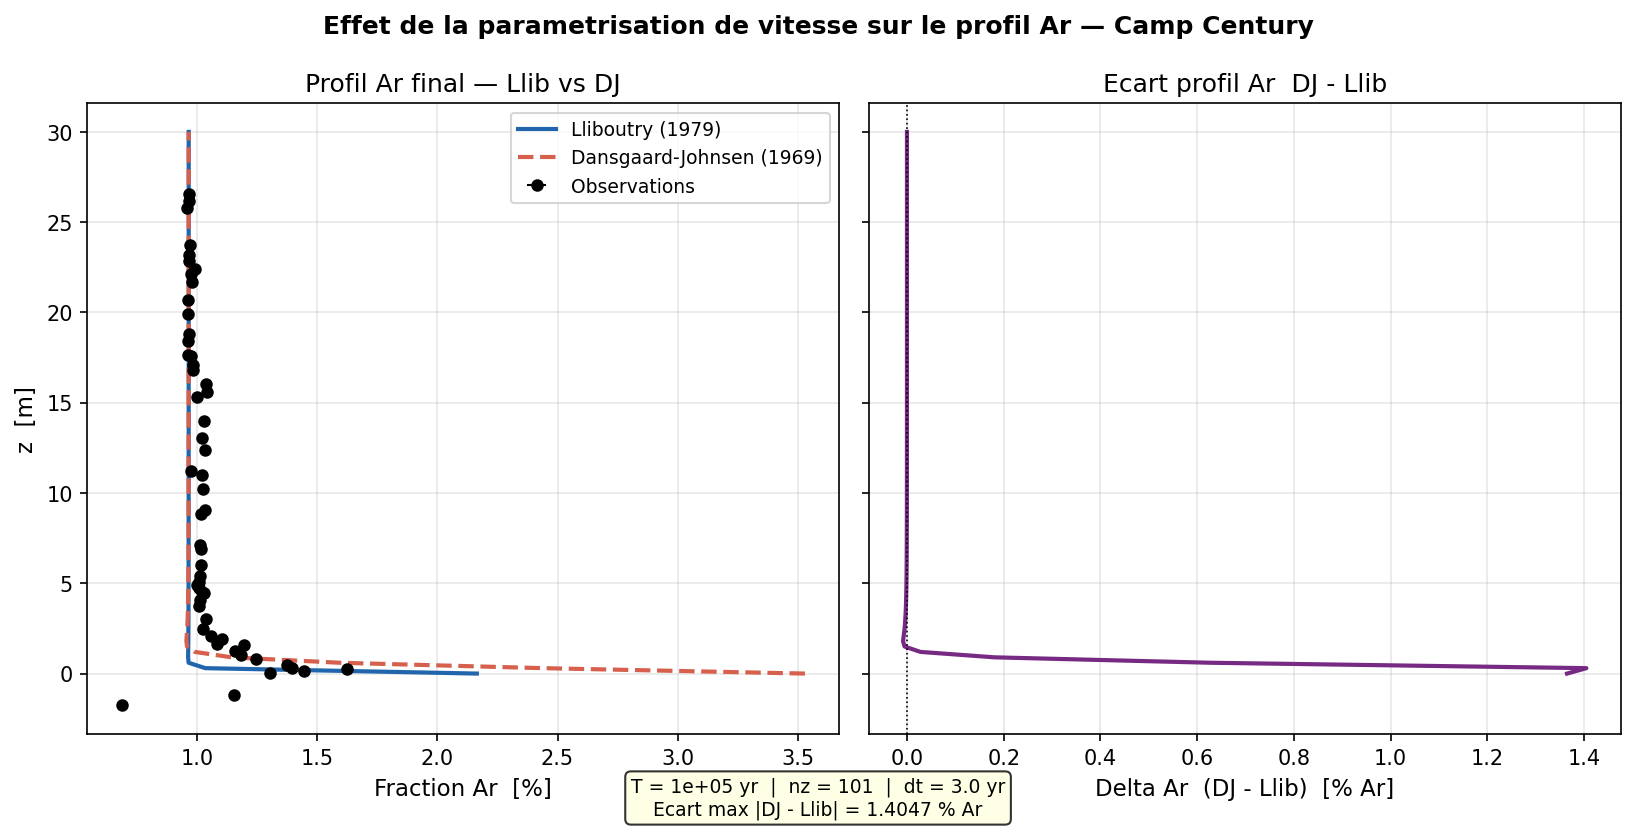

In [12]:
from IPython.display import Image, display
from glace.physics import velocity_dansgaard_johnsen, velocity_lliboutry

h_kink = 400.0  # m — Hammer et al. (1978)
u_llib_top = velocity_lliboutry(np.array([Z]), H_ice, b_acc, p_llib)[0]
u_dj_basal = -b_acc * h_kink / (2.0 * H_ice)
print(f'Umax Lliboutry = {u_llib_top*100:.4f} cm/yr')
print(f'Umax DJ        = {u_dj_basal*100:.4f} cm/yr')
print(f'Ecart relatif  = {abs(u_dj_basal - u_llib_top)/abs(u_llib_top)*100:.1f} %')
print()
print('--- Profils de vitesse ---')
display(Image(filename='../figures/fig_velocity_comparison.png', width=750))
print('--- Effet sur le profil Ar (T = 1e5 yr) ---')
display(Image(filename='../figures/fig_DJ_vs_llib_Ar.png', width=750))

## Attribution des processus
Compare : diffusion seule → + advection → + gas loss

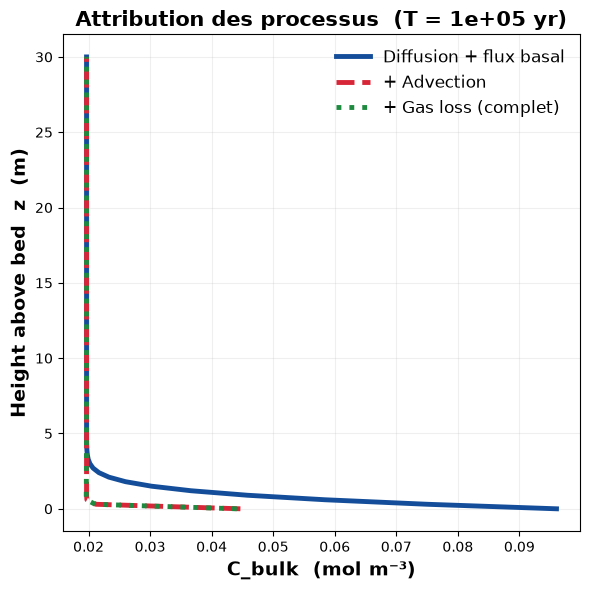

In [13]:
z = sim['z']

p1 = dict(sim); p1['u'] = np.zeros_like(sim['u']); p1['lambda_z'] = np.zeros_like(sim['lambda_z'])
p2 = dict(sim); p2['lambda_z'] = np.zeros_like(sim['lambda_z'])
p3 = dict(sim)

r1 = run_simulation(p1)
r2 = run_simulation(p2)
r3 = run_simulation(p3)

fig4 = plot_attribution(
    {'Diffusion + flux basal': r1['C_bulk'], '+ Advection': r2['C_bulk'], '+ Gas loss (complet)': r3['C_bulk']},
    z, title=f'Attribution des processus  (T = {T:.2g} yr)'
)
plt.show()

---
## Validation — Conservation de la masse

**Test** : u = 0, Q = 0, λ = 0, conditions de **zéro-flux aux deux bords**.  
Condition initiale non uniforme (gaussienne).  
→ la masse totale $\int C_{\mathrm{bulk}}\,dz$ doit rester **constante à la précision machine**.

Un schéma implicite avec flux nul aux frontières conserve exactement la masse
(la diffusion redistribue, ne crée ni ne détruit).

Conservation de masse — erreur relative max = 1.17e-07
  (rounding cumulatif du solveur, ~1e-14 par pas, s'accumule sur 1000 pas)


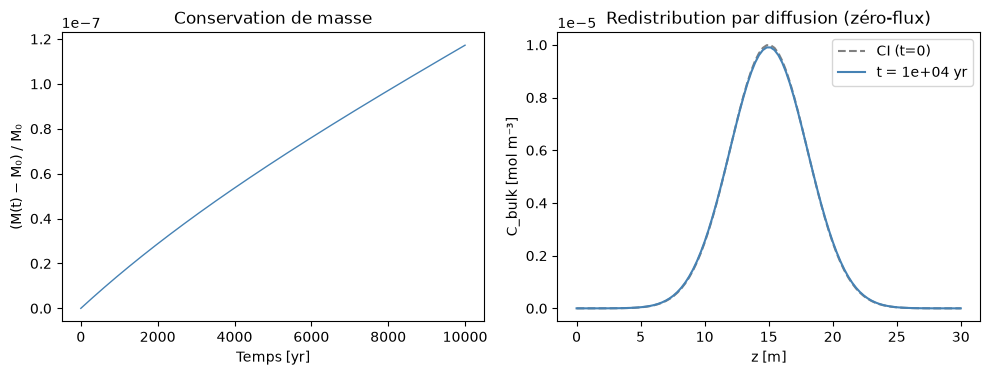

In [14]:
# ── Test : Conservation de la masse ──────────────────────────────────────────
# u=0, λ=0, zéro-flux aux deux bords → ∫ C_bulk dz = cte

nz_m  = 100; Z_m = 30.0; dz_m = Z_m / (nz_m - 1)
z_m   = np.linspace(0, Z_m, nz_m)
D_lat = D_m2s * 3.1536e7          # diffusivité réseau  [m² yr⁻¹]
pS_m  = P_diss * S_Ar * np.ones(nz_m)
n_air_m = TAC * rho_ice / Vm_STP

# CI : gaussienne centrée
z0_m = 15.0; sig_m = 3.0
Cbulk0_m = 1e-5 * np.exp(-(z_m - z0_m)**2 / (2 * sig_m**2))

# CL : zéro-flux aux deux bords
bc_sf_m = {'type': 'zeroflux'}
bc_bd_m = {'type': 'zeroflux'}

T_m = 1e4; dt_m = 10.0; nt_m = int(T_m / dt_m)
params_m = dict(
    z=z_m, dz=dz_m, dt=dt_m, nt=nt_m,
    u=np.zeros(nz_m), D=D_lat,
    pS=pS_m, n_air=n_air_m,
    bc_surf=bc_sf_m, bc_bed=bc_bd_m,
    lambda_z=np.zeros(nz_m), Cbulk0=Cbulk0_m,
)
result_m = run_simulation(params_m, return_full=True)

# Masse totale à chaque pas de temps
mass_t  = result_m['C_bulk'].sum(axis=0) * dz_m   # (nt+1,)
rel_err_m = np.abs((mass_t - mass_t[0]) / mass_t[0])
print(f'Conservation de masse — erreur relative max = {rel_err_m.max():.2e}')
print(f'  (rounding cumulatif du solveur, ~1e-14 par pas, s\'accumule sur {nt_m} pas)')

fig_m, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(result_m['t'], (mass_t / mass_t[0] - 1), lw=1, color='steelblue')
axes[0].set_xlabel('Temps [yr]')
axes[0].set_ylabel('(M(t) − M₀) / M₀')
axes[0].set_title('Conservation de masse')
axes[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

axes[1].plot(z_m, result_m['C_bulk'][:, 0],  ls='--', label='CI (t=0)', color='gray')
axes[1].plot(z_m, result_m['C_bulk'][:, -1], ls='-',  label=f't = {T_m:.0e} yr', color='steelblue')
axes[1].set_xlabel('z [m]')
axes[1].set_ylabel('C_bulk [mol m⁻³]')
axes[1].set_title('Redistribution par diffusion (zéro-flux)')
axes[1].legend()
plt.tight_layout(); plt.show()


---
## Validation — Solution analytique à l'état stationnaire

**Propriété** : la solution analytique stationnaire est un **point fixe** du schéma.

Avec u = 0, λ = 0, flux basal $F_b$ en bas, Dirichlet $C_{\mathrm{ice}}(Z)=0$ en haut :
$$C_{\mathrm{ice}}^{\mathrm{ss}}(z) = \frac{F_b}{D_{\mathrm{lat}}}\,(Z - z), 
\qquad C_{\mathrm{bulk}}^{\mathrm{ss}}(z) = \frac{F_b}{D_{\mathrm{eff}}}\,(Z - z)$$
où $D_{\mathrm{eff}} = \alpha \cdot D_{\mathrm{lat}}$ est la diffusivité effective (après partition).

**Test A** : initialiser depuis la solution exacte → erreur $\approx 0$ (point fixe).  
**Test B** : converger depuis zéro avec $D_{\mathrm{lat}}^{\times 100}$ pour accélérer la démonstration
(la partition réduit $D_{\mathrm{eff}} \approx 0.025 D_{\mathrm{lat}}$, ce qui rallonge le temps
de relaxation physique à $\tau_1 = 4Z^2/(\pi^2 D_{\mathrm{eff}}) \approx 10^8$ yr).  
Le taux de convergence est vérifié — pas les paramètres physiques.

alpha   = 0.02455
D_lat   = 3.1536e-04 m²/yr
D_eff   = 7.7420e-06 m²/yr

[Test A] Erreur depuis SS exacte (1000 pas) = 2.13e-16
  (attendu ≈ 0 — point fixe)

[Test B] D_eff = 7.7420e-04 m²/yr  (100× physique)
         τ₁ = 4.71e+05 yr
         T_run = 5τ₁ = 2.36e+06 yr  (47113 pas)
         Erreur relative max (après 5τ₁) = 8.77e-03
         (attendu ~ e⁻⁵ ≈ 0.7 %)


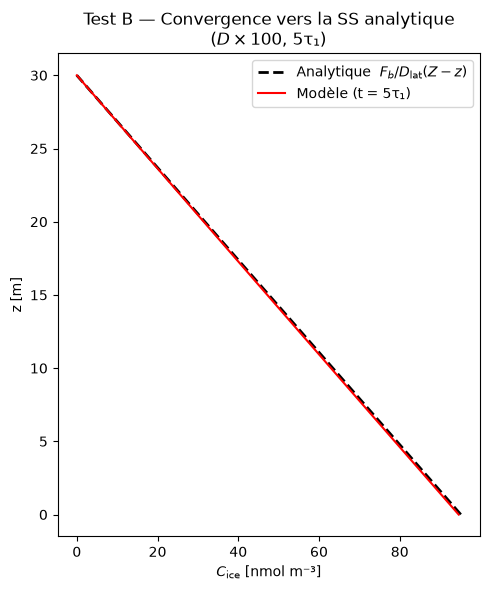

In [15]:
# ── Test A : solution analytique = point fixe du schéma ─────────────────────
nz_a = 50; Z_a = 30.0; dz_a = Z_a / (nz_a - 1)
z_a  = np.linspace(0, Z_a, nz_a)
pS_a    = P_diss * S_Ar * np.ones(nz_a)
n_air_a = TAC * rho_ice / Vm_STP
alpha_a = pS_a[0] / (pS_a[0] + n_air_a)
D_lat   = D_m2s * 3.1536e7         # diffusivité réseau  [m² yr⁻¹]
D_eff_a = alpha_a * D_lat           # diffusivité effective (partition)
print(f'alpha   = {alpha_a:.5f}')
print(f'D_lat   = {D_lat:.4e} m²/yr')
print(f'D_eff   = {D_eff_a:.4e} m²/yr')

F_b = 1e-10                # flux basal test  [mol m⁻² yr⁻¹]
C_ice_ss  = F_b / D_lat   * (Z_a - z_a)   # profil analytique sur C_ice
C_bulk_ss = F_b / D_eff_a * (Z_a - z_a)   # profil sur C_bulk (= C_ice_ss / alpha)
bc_sf_a = {'type': 'dirichlet', 'C': 0.0, 'C_ice': 0.0, 'F': 0.0}
bc_bd_a = {'type': 'flux',      'C': 0.0, 'C_ice': 0.0, 'F': F_b}

# Initialiser depuis la SS exacte — doit rester immobile
res_fp = run_simulation(dict(z=z_a, dz=dz_a, dt=500.0, nt=1000,
    u=np.zeros(nz_a), D=D_lat, pS=pS_a, n_air=n_air_a,
    bc_surf=bc_sf_a, bc_bed=bc_bd_a,
    lambda_z=np.zeros(nz_a), Cbulk0=C_bulk_ss))
err_fp = np.abs(res_fp['C_ice'] - C_ice_ss) / (np.abs(C_ice_ss) + 1e-30)
print(f'\n[Test A] Erreur depuis SS exacte (1000 pas) = {err_fp.max():.2e}')
print(f'  (attendu ≈ 0 — point fixe)')  

# ── Test B : convergence depuis zéro, D ×100 pour accélérer ──────────────────
# (test numérique uniquement — vérifie le taux de convergence, pas les valeurs physiques)
D_lat_B = 100 * D_lat                 # diffusivité amplifiée pour le test
D_eff_B = alpha_a * D_lat_B
C_ice_B  = F_b / D_lat_B * (Z_a - z_a)   # SS analytique pour D×100
C_bulk_B = F_b / D_eff_B * (Z_a - z_a)

# τ₁ = 4Z²/(π²D_eff) pour CL mixte (Dirichlet haut, Neumann bas)
tau1_B = 4 * Z_a**2 / (np.pi**2 * D_eff_B)
dt_B  = 50.0
nt_B  = int(5 * tau1_B / dt_B)
T_B   = nt_B * dt_B
print(f'\n[Test B] D_eff = {D_eff_B:.4e} m²/yr  (100× physique)')
print(f'         τ₁ = {tau1_B:.2e} yr')
print(f'         T_run = 5τ₁ = {T_B:.2e} yr  ({nt_B} pas)')

res_B = run_simulation(dict(z=z_a, dz=dz_a, dt=dt_B, nt=nt_B,
    u=np.zeros(nz_a), D=D_lat_B, pS=pS_a, n_air=n_air_a,
    bc_surf=bc_sf_a, bc_bed=bc_bd_a,
    lambda_z=np.zeros(nz_a), Cbulk0=np.zeros(nz_a)))

mask_B = C_ice_B > C_ice_B.max() * 1e-3
err_B  = np.abs(res_B['C_ice'][mask_B] - C_ice_B[mask_B]) / C_ice_B[mask_B]
print(f'         Erreur relative max (après 5τ₁) = {err_B.max():.2e}')
print(f'         (attendu ~ e⁻⁵ ≈ 0.7 %)')

fig_a, ax = plt.subplots(figsize=(5, 6))
ax.plot(C_ice_B * 1e9, z_a, 'k--', lw=2, label='Analytique  $F_b/D_{\\mathrm{lat}}(Z-z)$')
ax.plot(res_B['C_ice'] * 1e9, z_a, 'r-', lw=1.5, label='Modèle (t = 5τ₁)')
ax.set_xlabel('$C_{\\mathrm{ice}}$ [nmol m⁻³]')
ax.set_ylabel('z [m]')
ax.set_title('Test B — Convergence vers la SS analytique\n($D \\times 100$, 5τ₁)')
ax.legend()
plt.tight_layout(); plt.show()
